# Лабораторная работа на лекции

Задача состоит в детектировании фрутов и их классификации. В рамках задачи есть 3 инварианта:
  - более-менее однотонный стол (это наш фон). При этом мы не можем полагаться на то, что мы заранее знаем цвет фона. Также на поверхности могут быть блики;
  - в любой момент времени фрукты занимают не более половины всего стола;
  - известен набор фруктов: мандарин, лимон, банан, красное яблоко.

Мы также заранее не знаем статичны ли камера и фрукты. В теории всё может двигаться.

## 1. Выбор цвета фона

Хоть стол и однотонный сам со себе, он не явялется однородным, поэтому имеет смысл искать не точное совпадение цветов, а большое отличие от фона.

Из условия, что стол всё время виден как минимум на половину, мы можем определить его цвет как медиану значений цветовых каналов. Но на видео вдобавок есть много пикселей, которые не являются столом, поэтому для нахождения цвета стола, будет анализировать только центральную часть исходного изображения.

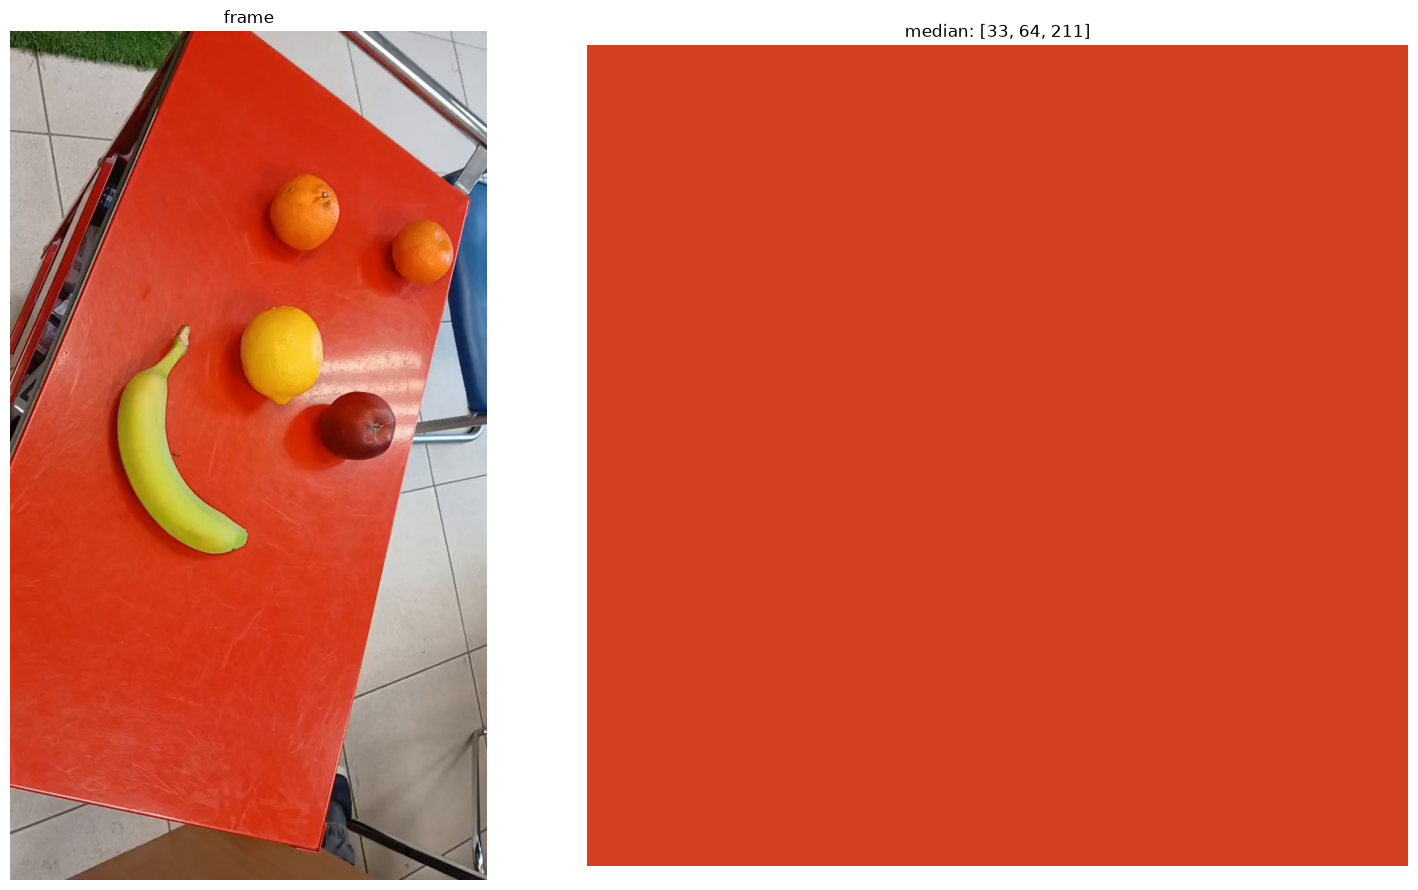

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

path = "./fruits.mp4"
cam = cv2.VideoCapture(path)

ret, frame = cam.read()
cam.release()

h, w = frame.shape[:2]
x1, x2 = int(w * 0.20), int(w * 0.85)
y1, y2 = int(h * 0.20), int(h * 0.85)
center = frame[y1:y2, x1:x2]

hsv = cv2.cvtColor(center, cv2.COLOR_BGR2HSV)
pixels = center.reshape(-1, 3)
median = np.median(pixels, axis=0).astype(np.uint8)

background_color = np.zeros((10, 10, 3), dtype=np.uint8)
background_color[:] = median

fig, axes = plt.subplots(1, 2, figsize=(16, 9))

axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
axes[0].set_title("frame")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(background_color, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"median: [{median[0]}, {median[1]}, {median[2]}]")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 2. Исследование каналов HSV по отдельности

Хочется определить, какие каналы лучше подходят для выделения поверхности стола. Для каждого пикселя рассчитываю отклонения по каналам H, S, V от найденного медианного цвета. На основе отклонений определяю пороговые значения, после чего для каждого канала строю бинарные маски.


### Определение пороговых значений

Для каждого пикселя вычисляются абсолютные отклонения `diff_H`, `diff_S`, `diff_V` от медианного цвета стола в пространстве HSV. Для `H` цикличность учитывается.

Далее для каждого канала определяется разброс --- медиана отклонений в центральной области кадра:

$$
\text{spread}_i = \text{median}(\text{diff}_i)
$$

На основе разброса автоматически вычисляются допустимые отклонения:

$$
\text{limit}_i = \max(T_{\min},\ 3\cdot \text{spread}_i),
$$

где минимальный порог $T_{\min} = 3$ для `H` и $T_{\min} = 10$ для `S` и `V`. Коэффициенты выбраны эвристически.

Бинарная маска строится по условию:

$$
\text{mask}_i(x,y)=
\begin{cases}
255, & \text{diff}_i(x,y)\leqslant \text{limit}_i\\
0, & \text{diff}_i(x,y)>\text{limit}_i
\end{cases}
$$

Таким образом, белые пиксели соответствуют участкам, близким по выбранному каналу к цвету стола, а чёрные --- участкам с большим отклонением.

Орлиным взглядом было установлено, что отдельные каналы не обеспечивают достаточно качественного выделения стола. Некоторые участки поверхности теряются из-за бликов и неравномерного освещения.

In [96]:
import cv2
import numpy as np


def get_median_color(frame):
    h, w = frame.shape[:2]

    x1, x2 = int(w * 0.20), int(w * 0.85)
    y1, y2 = int(h * 0.20), int(h * 0.85)

    center = frame[y1:y2, x1:x2]

    pixels = center.reshape(-1, 3)
    median = np.median(pixels, axis=0).astype(np.uint8)

    median_hsv = cv2.cvtColor(median.reshape(1, 1, 3), cv2.COLOR_BGR2HSV)[0, 0]

    return median_hsv, (x1, x2, y1, y2)


def get_masks(frame, median_hsv, region):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    x1, x2, y1, y2 = region

    diff_h = np.abs(hsv[:, :, 0].astype(np.int16) - int(median_hsv[0]))
    diff_h = np.minimum(diff_h, 180 - diff_h)

    diff_s = np.abs(hsv[:, :, 1].astype(np.int16) - int(median_hsv[1]))
    diff_v = np.abs(hsv[:, :, 2].astype(np.int16) - int(median_hsv[2]))

    spread_h = np.median(diff_h[y1:y2, x1:x2])
    spread_s = np.median(diff_s[y1:y2, x1:x2])
    spread_v = np.median(diff_v[y1:y2, x1:x2])

    limit_h = max(3, int(3 * spread_h))
    limit_s = max(10, int(3 * spread_s))
    limit_v = max(10, int(3 * spread_v))

    mask_h = cv2.inRange(diff_h.astype(np.uint8), 0, limit_h)
    mask_s = cv2.inRange(diff_s.astype(np.uint8), 0, limit_s)
    mask_v = cv2.inRange(diff_v.astype(np.uint8), 0, limit_v)

    return mask_h, mask_s, mask_v


def show_frames(frame, mask_h, mask_s, mask_v):
    h, w = frame.shape[:2]

    mask_h = cv2.cvtColor(mask_h, cv2.COLOR_GRAY2BGR)
    mask_s = cv2.cvtColor(mask_s, cv2.COLOR_GRAY2BGR)
    mask_v = cv2.cvtColor(mask_v, cv2.COLOR_GRAY2BGR)

    # Тут просто уменьшаю изображения
    scale = min(1.0, 550 / h)
    size = (int(w * scale), int(h * scale))

    frame_small = cv2.resize(frame, size)
    mask_h_small = cv2.resize(mask_h, size)
    mask_s_small = cv2.resize(mask_s, size)
    mask_v_small = cv2.resize(mask_v, size)

    result = cv2.hconcat([frame_small, mask_h_small, mask_s_small, mask_v_small])

    cv2.imshow("frame | H | S | V", result)


path = "./fruits.mp4"
cam = cv2.VideoCapture(path)

paused = False

while True:
    if not paused:
        ret, frame = cam.read()

        if not ret:
            cam.release()
            cam = cv2.VideoCapture(path)

            if not cam.isOpened():
                break

            continue

        median_hsv, region = get_median_color(frame)
        mask_h, mask_s, mask_v = get_masks(frame, median_hsv, region)

        show_frames(frame, mask_h, mask_s, mask_v)

    key = cv2.waitKey(0 if paused else 30) & 0xFF
    if key == ord("q"):
        break
    if key == ord(" "):
        paused = not paused

cam.release()
cv2.destroyAllWindows()

## 3. Исследование линейной комбинации каналов HSV

Используем линейную комбинацию нормированных отклонений с весами от характерного цвета стола:

$$
D = w_H\cdot\frac{D_H}{T_H} + w_S\cdot\frac{D_S}{T_S}+w_V\cdot\frac{D_V}{T_V},
$$

где $(D_H,D_S,D_V)$ --- отклонения по соответствующим каналам, $(T_H,T_S,T_V)$ --- вычисленные пороги, а $(w_H,w_S,w_V)$ --- весовые коэффициенты. Пиксели, для которых $(D\leqslant1)$, относятся к поверхности стола.


Сугубо эмпирически было установлено, что наиболее подходящими оказались следующие значения:

$$
\boxed{w_H=0.75,\quad w_S=0,\quad w_V=0.5}.
$$

In [73]:
import cv2
import numpy as np


def get_median_color(frame):
    h, w = frame.shape[:2]

    x1, x2 = int(w * 0.20), int(w * 0.85)
    y1, y2 = int(h * 0.20), int(h * 0.85)

    center = frame[y1:y2, x1:x2]

    pixels = center.reshape(-1, 3)
    median = np.median(pixels, axis=0).astype(np.uint8)

    median_hsv = cv2.cvtColor(median.reshape(1, 1, 3), cv2.COLOR_BGR2HSV)[0, 0]

    return median_hsv, (x1, x2, y1, y2)


def get_mask(frame, median_hsv, region, weights):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    x1, x2, y1, y2 = region
    weight_h, weight_s, weight_v = weights

    diff_h = np.abs(hsv[:, :, 0].astype(np.int16) - int(median_hsv[0]))
    diff_h = np.minimum(diff_h, 180 - diff_h)

    diff_s = np.abs(hsv[:, :, 1].astype(np.int16) - int(median_hsv[1]))
    diff_v = np.abs(hsv[:, :, 2].astype(np.int16) - int(median_hsv[2]))

    spread_h = np.median(diff_h[y1:y2, x1:x2])
    spread_s = np.median(diff_s[y1:y2, x1:x2])
    spread_v = np.median(diff_v[y1:y2, x1:x2])

    limit_h = max(3, int(3 * spread_h))
    limit_s = max(10, int(3 * spread_s))
    limit_v = max(10, int(3 * spread_v))

    diff = (
        weight_h * diff_h / limit_h
        + weight_s * diff_s / limit_s
        + weight_v * diff_v / limit_v
    )

    mask = (diff <= 1).astype(np.uint8) * 255

    return mask


def show_frames(frame, mask):
    h, w = frame.shape[:2]

    mask_bgr = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)

    # Тут просто уменьшаю изображения
    scale = min(1.0, 550 / h)
    size = (int(w * scale), int(h * scale))

    frame_small = cv2.resize(frame, size)
    mask_small = cv2.resize(mask_bgr, size)

    result = cv2.hconcat([frame_small, mask_small])

    cv2.imshow("frame | mask", result)


path = "./fruits.mp4"
cam = cv2.VideoCapture(path)

cv2.namedWindow("frame | mask", cv2.WINDOW_AUTOSIZE)

cv2.createTrackbar("H", "frame | mask", 75, 100, lambda x: None)
cv2.createTrackbar("S", "frame | mask", 0, 100, lambda x: None)
cv2.createTrackbar("V", "frame | mask", 50, 100, lambda x: None)

paused = False

while True:
    if not paused:
        ret, frame = cam.read()

        if not ret:
            cam.set(cv2.CAP_PROP_POS_FRAMES, 0)

            ret, frame = cam.read()

            if not ret:
                break

    weight_h = cv2.getTrackbarPos("H", "frame | mask") / 100
    weight_s = cv2.getTrackbarPos("S", "frame | mask") / 100
    weight_v = cv2.getTrackbarPos("V", "frame | mask") / 100

    median_hsv, region = get_median_color(frame)

    weights = (weight_h, weight_s, weight_v)
    mask = get_mask(frame, median_hsv, region, weights)

    show_frames(frame, mask)

    key = cv2.waitKey(0 if paused else 30) & 0xFF
    if key == ord("q"):
        break
    if key == ord(" "):
        paused = not paused

cam.release()
cv2.destroyAllWindows()

## 4. Выделение кандидатов

- После получения бинарной маски стола с выбранными весами оставляю самую крупную связную область. Я предполагаю, что она соответствует поверхности стола по условию задачи.

- Далее работаю с морфологией. Затем с помощью `cv2.floodFill()` (идея взята из книги `Introduction to CV` от Stan Birchfield) заполняю замкнутые чёрные области внутри стола. 

- Потом вычитаю исходную маску из заполненной, получаю кандидатов на фрукты.

- В конце снова применяю морфологию.

- Полученная маска приблизительно выделяет фрукты. В неё также могут попадать блики и дефекты из-за поворота камеры. Поэтому далее будет фильтрация областей.

In [81]:
import cv2
import numpy as np


def get_median_color(frame):
    h, w = frame.shape[:2]

    x1, x2 = int(w * 0.20), int(w * 0.85)
    y1, y2 = int(h * 0.20), int(h * 0.85)

    center = frame[y1:y2, x1:x2]

    pixels = center.reshape(-1, 3)
    median = np.median(pixels, axis=0).astype(np.uint8)

    median_hsv = cv2.cvtColor(median.reshape(1, 1, 3), cv2.COLOR_BGR2HSV)[0, 0]

    return median_hsv, (x1, x2, y1, y2)


def get_mask(frame, median_hsv, region):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    x1, x2, y1, y2 = region

    diff_h = np.abs(hsv[:, :, 0].astype(np.int16) - int(median_hsv[0]))
    diff_h = np.minimum(diff_h, 180 - diff_h)

    diff_v = np.abs(hsv[:, :, 2].astype(np.int16) - int(median_hsv[2]))

    spread_h = np.median(diff_h[y1:y2, x1:x2])
    spread_v = np.median(diff_v[y1:y2, x1:x2])

    limit_h = max(3, int(3 * spread_h))
    limit_v = max(10, int(3 * spread_v))

    diff = 0.75 * diff_h / limit_h + 0.5 * diff_v / limit_v

    mask = (diff <= 1).astype(np.uint8) * 255

    return mask


def get_main_component(mask):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask)

    main_mask = np.zeros_like(mask)

    if num_labels > 1:
        areas = stats[1:, cv2.CC_STAT_AREA]
        largest_label = np.argmax(areas) + 1

        main_mask[labels == largest_label] = 255

    return main_mask


def fill_holes(mask):
    h, w = mask.shape

    padded = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)

    flood = padded.copy()
    flood_mask = np.zeros((h + 4, w + 4), dtype=np.uint8)

    cv2.floodFill(flood, flood_mask, (0, 0), 255)

    holes = cv2.bitwise_not(flood)[1:-1, 1:-1]

    filled_mask = cv2.bitwise_or(mask, holes)

    return filled_mask


def get_candidates(main_mask):
    kernel = np.ones((15, 15), np.uint8)

    closed_mask = cv2.morphologyEx(main_mask, cv2.MORPH_OPEN, kernel)
    closed_mask = cv2.morphologyEx(main_mask, cv2.MORPH_CLOSE, kernel)

    filled_mask = fill_holes(closed_mask)

    candidates = cv2.subtract(filled_mask, closed_mask)

    candidates = cv2.morphologyEx(candidates, cv2.MORPH_OPEN, kernel)
    candidates = cv2.morphologyEx(
        candidates, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)
    )

    return closed_mask, candidates


def show_frames(frame, main_mask, closed_mask, candidates):
    h, w = frame.shape[:2]

    main_mask = cv2.cvtColor(main_mask, cv2.COLOR_GRAY2BGR)
    closed_mask = cv2.cvtColor(closed_mask, cv2.COLOR_GRAY2BGR)
    candidates = cv2.cvtColor(candidates, cv2.COLOR_GRAY2BGR)

    # Тут просто уменьшаю изображения
    scale = min(1.0, 550 / h, 1600 / (4 * w))
    size = (int(w * scale), int(h * scale))

    frame_small = cv2.resize(frame, size)
    main_mask_small = cv2.resize(main_mask, size)
    closed_mask_small = cv2.resize(closed_mask, size)
    candidates_small = cv2.resize(candidates, size)

    result = cv2.hconcat(
        [frame_small, main_mask_small, closed_mask_small, candidates_small]
    )

    cv2.imshow("frame | main mask | closing | candidates", result)


path = "./fruits.mp4"
cam = cv2.VideoCapture(path)

paused = False

while True:
    if not paused:
        ret, frame = cam.read()

        if not ret:
            cam.release()
            cam = cv2.VideoCapture(path)

            if not cam.isOpened():
                break

            continue

        median_hsv, region = get_median_color(frame)

        mask = get_mask(frame, median_hsv, region)
        main_mask = get_main_component(mask)
        closed_mask, candidates = get_candidates(main_mask)

        show_frames(frame, main_mask, closed_mask, candidates)

    key = cv2.waitKey(0 if paused else 30) & 0xFF
    if key == ord("q"):
        break
    if key == ord(" "):
        paused = not paused

cam.release()
cv2.destroyAllWindows()

## 5. Получение bbox

- Определяем размеры и площадь каждой связной области.

- Для уменьшения количества ложных обнаружений добавляю фильтрацию по минимальной и максимальной площади. Пороговые значения задаются относительно площади кадра и регулируются с помощью ползунков min_area и max_area. Экспериментально были выбраны значения 0.3% и 4.5% площади кадра соответственно.

- Также замечаю, что иногда один фрукт разделяется на несколько небольших областей из-за плохо найденной маски. Поэтому добавляю функцию `merge_boxes()`, которая объединяет близко расположенные небольшие компоненты в один минимальный охватывающий прямоугольник. Допустимое расстояние между ними составляет 2% от размера кадра.

In [ ]:
import cv2
import numpy as np


def get_median_color(frame):
    h, w = frame.shape[:2]

    x1, x2 = int(w * 0.20), int(w * 0.85)
    y1, y2 = int(h * 0.20), int(h * 0.85)

    center = frame[y1:y2, x1:x2]

    pixels = center.reshape(-1, 3)
    median = np.median(pixels, axis=0).astype(np.uint8)

    median_hsv = cv2.cvtColor(median.reshape(1, 1, 3), cv2.COLOR_BGR2HSV)[0, 0]

    return median_hsv, (x1, x2, y1, y2)


def get_mask(frame, median_hsv, region):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    x1, x2, y1, y2 = region

    diff_h = np.abs(hsv[:, :, 0].astype(np.int16) - int(median_hsv[0]))
    diff_h = np.minimum(diff_h, 180 - diff_h)

    diff_v = np.abs(hsv[:, :, 2].astype(np.int16) - int(median_hsv[2]))

    spread_h = np.median(diff_h[y1:y2, x1:x2])
    spread_v = np.median(diff_v[y1:y2, x1:x2])

    limit_h = max(3, int(3 * spread_h))
    limit_v = max(10, int(3 * spread_v))

    diff = 0.75 * diff_h / limit_h + 0.5 * diff_v / limit_v

    mask = (diff <= 1).astype(np.uint8) * 255

    return mask


def get_main_component(mask):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask)

    main_mask = np.zeros_like(mask)

    if num_labels > 1:
        areas = stats[1:, cv2.CC_STAT_AREA]
        largest_label = np.argmax(areas) + 1

        main_mask[labels == largest_label] = 255

    return main_mask


def fill_holes(mask):
    h, w = mask.shape

    padded = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)

    flood = padded.copy()
    flood_mask = np.zeros((h + 4, w + 4), dtype=np.uint8)

    cv2.floodFill(flood, flood_mask, (0, 0), 255)

    holes = cv2.bitwise_not(flood)[1:-1, 1:-1]

    filled_mask = cv2.bitwise_or(mask, holes)

    return filled_mask


def get_candidates(main_mask):
    kernel = np.ones((15, 15), np.uint8)

    closed_mask = cv2.morphologyEx(main_mask, cv2.MORPH_CLOSE, kernel)

    filled_mask = fill_holes(closed_mask)

    candidates = cv2.subtract(filled_mask, closed_mask)

    candidates = cv2.morphologyEx(candidates, cv2.MORPH_OPEN, kernel)
    candidates = cv2.morphologyEx(
        candidates, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)
    )

    return candidates


def merge_boxes(regions, max_area, gap):
    changed = True

    while changed:
        changed = False

        for i in range(len(regions)):
            for j in range(i + 1, len(regions)):
                x1, y1, w1, h1, area1 = regions[i]
                x2, y2, w2, h2, area2 = regions[j]

                if area1 > max_area / 7 or area2 > max_area / 7:
                    continue

                dx = max(0, x1 - (x2 + w2), x2 - (x1 + w1))
                dy = max(0, y1 - (y2 + h2), y2 - (y1 + h1))

                if dx > gap or dy > gap:
                    continue

                if area1 + area2 > max_area:
                    continue

                x = min(x1, x2)
                y = min(y1, y2)

                width = max(x1 + w1, x2 + w2) - x
                height = max(y1 + h1, y2 + h2) - y

                regions[i] = (x, y, width, height, area1 + area2)
                regions.pop(j)

                changed = True
                break

            if changed:
                break

    return regions


def get_area_limits(frame):
    h, w = frame.shape[:2]

    window = "frame | candidates | bounding boxes"
    min_area = max(1, int(h * w * cv2.getTrackbarPos("min area", window) / 10000))
    max_area = max(1, int(h * w * cv2.getTrackbarPos("max area", window) / 10000))

    return min_area, max_area


def get_boxes(candidates, min_area, max_area):
    h, w = candidates.shape

    num_labels, _, stats, _ = cv2.connectedComponentsWithStats(candidates)

    regions = []

    min_fragment = max(1, min_area // 3)

    for i in range(1, num_labels):
        x, y, width, height, area = stats[i]

        if area < min_fragment or area > max_area:
            continue

        regions.append((x, y, width, height, area))

    gap = max(2, int(min(h, w) * 0.02))

    regions = merge_boxes(regions, max_area, gap)

    boxes = []

    for x, y, width, height, area in regions:
        if min_area <= area <= max_area:
            boxes.append((x, y, width, height))

    return boxes


def show_frames(frame, candidates, boxes):
    h, w = frame.shape[:2]

    result_frame = frame.copy()

    for x, y, width, height in boxes:
        cv2.rectangle(result_frame, (x, y), (x + width, y + height), (0, 255, 0), 2)

    candidates = cv2.cvtColor(candidates, cv2.COLOR_GRAY2BGR)

    # Тут просто уменьшаю изображения
    scale = min(1.0, 550 / h, 1500 / (3 * w))
    size = (int(w * scale), int(h * scale))

    frame_small = cv2.resize(frame, size)
    candidates_small = cv2.resize(candidates, size, interpolation=cv2.INTER_NEAREST)
    result_small = cv2.resize(result_frame, size)

    result = cv2.hconcat([frame_small, candidates_small, result_small])

    cv2.imshow("frame | candidates | bounding boxes", result)


path = "./fruits.mp4"
cam = cv2.VideoCapture(path)

cv2.namedWindow("frame | candidates | bounding boxes", cv2.WINDOW_AUTOSIZE)

cv2.createTrackbar(
    "min area", "frame | candidates | bounding boxes", 30, 300, lambda x: None
)

cv2.createTrackbar(
    "max area", "frame | candidates | bounding boxes", 450, 1000, lambda x: None
)

paused = False

while True:
    if not paused:
        ret, frame = cam.read()

        if not ret:
            cam.release()
            cam = cv2.VideoCapture(path)

            if not cam.isOpened():
                break

            continue

    min_area, max_area = get_area_limits(frame)

    median_hsv, region = get_median_color(frame)

    mask = get_mask(frame, median_hsv, region)
    main_mask = get_main_component(mask)
    candidates = get_candidates(main_mask)

    boxes = get_boxes(candidates, min_area, max_area)

    show_frames(frame, candidates, boxes)

    key = cv2.waitKey(30) & 0xFF
    if key == ord("q"):
        break
    if key == ord(" "):
        paused = not paused

cam.release()
cv2.destroyAllWindows()

## 6. Классификация фруктов

По условию задачи есть четыре класса фруктов: банан, лимон, мандарин и красное яблоко.

- Для каждого объекта выделяю область внутри bbox и перевожу его в HSV. Учитываю только пиксели, принадлежащие маске фрукта, чтобы исключить влияние цвета стола.

- Затем вычисляю доли красных, оранжевых и жёлтых пикселей. Также вычисляю отношение сторон прямоугольника и степень его заполненности.

- Задаю правила классификации: банан отличается вытянутой формой и небольшой заполненностью bbox, лимон --- жёлтым цветом, мандарин --- оранжевым цветом, а красное яблоко --- красным цветом и относительно низкой яркостью.

- Если объект не удовлетворяет ни одному из условий, он остаётся без класса. А значит, что на этом этапе отсеялись все ложноположительные срабатывания для bbox.


In [97]:
import cv2
import numpy as np


def get_median_color(frame):
    h, w = frame.shape[:2]

    x1, x2 = int(w * 0.20), int(w * 0.85)
    y1, y2 = int(h * 0.20), int(h * 0.85)

    center = frame[y1:y2, x1:x2]

    pixels = center.reshape(-1, 3)
    median = np.median(pixels, axis=0).astype(np.uint8)

    median_hsv = cv2.cvtColor(median.reshape(1, 1, 3), cv2.COLOR_BGR2HSV)[0, 0]

    return median_hsv, (x1, x2, y1, y2)


def get_mask(frame, median_hsv, region):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

    x1, x2, y1, y2 = region

    diff_h = np.abs(hsv[:, :, 0].astype(np.int16) - int(median_hsv[0]))
    diff_h = np.minimum(diff_h, 180 - diff_h)

    diff_v = np.abs(hsv[:, :, 2].astype(np.int16) - int(median_hsv[2]))

    spread_h = np.median(diff_h[y1:y2, x1:x2])
    spread_v = np.median(diff_v[y1:y2, x1:x2])

    limit_h = max(3, int(3 * spread_h))
    limit_v = max(10, int(3 * spread_v))

    diff = 0.75 * diff_h / limit_h + 0.5 * diff_v / limit_v

    mask = (diff <= 1).astype(np.uint8) * 255

    return mask


def get_main_component(mask):
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask)

    main_mask = np.zeros_like(mask)

    if num_labels > 1:
        areas = stats[1:, cv2.CC_STAT_AREA]
        largest_label = np.argmax(areas) + 1

        main_mask[labels == largest_label] = 255

    return main_mask


def fill_holes(mask):
    h, w = mask.shape

    padded = cv2.copyMakeBorder(mask, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)

    flood = padded.copy()
    flood_mask = np.zeros((h + 4, w + 4), dtype=np.uint8)

    cv2.floodFill(flood, flood_mask, (0, 0), 255)

    holes = cv2.bitwise_not(flood)[1:-1, 1:-1]

    filled_mask = cv2.bitwise_or(mask, holes)

    return filled_mask


def get_candidates(main_mask):
    kernel = np.ones((15, 15), np.uint8)

    closed_mask = cv2.morphologyEx(main_mask, cv2.MORPH_CLOSE, kernel)

    filled_mask = fill_holes(closed_mask)

    candidates = cv2.subtract(filled_mask, closed_mask)

    candidates = cv2.morphologyEx(candidates, cv2.MORPH_OPEN, kernel)
    candidates = cv2.morphologyEx(
        candidates, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)
    )

    return candidates


def merge_boxes(regions, max_area, gap):
    changed = True

    while changed:
        changed = False

        for i in range(len(regions)):
            for j in range(i + 1, len(regions)):
                x1, y1, w1, h1, area1 = regions[i]
                x2, y2, w2, h2, area2 = regions[j]

                if area1 > max_area / 7 or area2 > max_area / 7:
                    continue

                dx = max(0, x1 - (x2 + w2), x2 - (x1 + w1))
                dy = max(0, y1 - (y2 + h2), y2 - (y1 + h1))

                if dx > gap or dy > gap:
                    continue

                if area1 + area2 > max_area:
                    continue

                x = min(x1, x2)
                y = min(y1, y2)

                width = max(x1 + w1, x2 + w2) - x
                height = max(y1 + h1, y2 + h2) - y

                regions[i] = (x, y, width, height, area1 + area2)
                regions.pop(j)

                changed = True
                break

            if changed:
                break

    return regions


def get_area_limits(frame):
    h, w = frame.shape[:2]

    min_area = max(1, int(h * w * 0.003))
    max_area = max(1, int(h * w * 0.045))

    return min_area, max_area


def get_boxes(candidates, min_area, max_area):
    h, w = candidates.shape

    num_labels, _, stats, _ = cv2.connectedComponentsWithStats(candidates)

    regions = []

    min_fragment = max(1, min_area // 3)

    for i in range(1, num_labels):
        x, y, width, height, area = stats[i]

        if area < min_fragment or area > max_area:
            continue

        regions.append((x, y, width, height, area))

    gap = max(2, int(min(h, w) * 0.02))

    regions = merge_boxes(regions, max_area, gap)

    boxes = []

    for x, y, width, height, area in regions:
        if min_area <= area <= max_area:
            boxes.append((x, y, width, height))

    return boxes


def classify_fruit(frame, candidates, box):
    x, y, width, height = box

    roi = frame[y : y + height, x : x + width]
    mask_roi = candidates[y : y + height, x : x + width]

    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)

    pixels = hsv[mask_roi > 0]

    if len(pixels) == 0:
        return None

    h = pixels[:, 0]
    s = pixels[:, 1]
    v = pixels[:, 2]

    red = np.mean(((h <= 9) | (h >= 170)) & (s >= 80))
    orange = np.mean((h >= 10) & (h < 19) & (s >= 80))
    yellow = np.mean((h >= 19) & (h < 45) & (s >= 80))

    ratio = max(width, height) / max(1, min(width, height))
    fill_ratio = len(pixels) / (width * height)

    median_v = np.median(v)

    if yellow > 0.35 and fill_ratio < 0.55 and ratio > 1.15:
        return "Банан"

    if yellow > 0.55 and fill_ratio > 0.57:
        return "Лимон"

    if orange > 0.50 and fill_ratio > 0.50:
        return "Мандарин"

    if red > 0.65 and median_v < 190 and fill_ratio > 0.55 and ratio < 1.40:
        return "Красное яблоко"

    return None


def show_frames(frame, candidates, boxes):
    result_frame = frame.copy()

    for x, y, width, height in boxes:
        fruit = classify_fruit(frame, candidates, (x, y, width, height))

        if fruit is None:
            continue

        cv2.rectangle(result_frame, (x, y), (x + width, y + height), (0, 255, 0), 2)

        cv2.putText(
            result_frame,
            fruit,
            (x, max(25, y - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2,
        )

    cv2.imshow("fruits", result_frame)


path = "./fruits.mp4"
cam = cv2.VideoCapture(path)

paused = False

while True:
    if not paused:
        ret, frame = cam.read()

        if not ret:
            cam.release()
            cam = cv2.VideoCapture(path)

            if not cam.isOpened():
                break

            continue

    min_area, max_area = get_area_limits(frame)

    median_hsv, region = get_median_color(frame)

    mask = get_mask(frame, median_hsv, region)
    main_mask = get_main_component(mask)
    candidates = get_candidates(main_mask)

    boxes = get_boxes(candidates, min_area, max_area)

    show_frames(frame, candidates, boxes)

    key = cv2.waitKey(30) & 0xFF
    if key == ord("q"):
        break
    if key == ord(" "):
        paused = not paused

cam.release()
cv2.destroyAllWindows()